Int8 Quantization

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1.0,1.0,100)

x[:10]

array([-1.        , -0.97979798, -0.95959596, -0.93939394, -0.91919192,
       -0.8989899 , -0.87878788, -0.85858586, -0.83838384, -0.81818182])

In [2]:
min_x = -1.0
max_x = 1.0
qmin = -128
qmax =127

scale = (max_x - min_x) / (qmax - qmin) # step size for quantization
scale

0.00784313725490196

In [3]:
zero_point = 0

q = np.round((x-zero_point)/scale).astype(int)

q = np.clip(q, qmin, qmax)

q[:10]

array([-128, -125, -122, -120, -117, -115, -112, -109, -107, -104])

In [4]:
# Dequantization int8 --> float
x_hat = scale*(q-zero_point)
x_hat[:10]

array([-1.00392157, -0.98039216, -0.95686275, -0.94117647, -0.91764706,
       -0.90196078, -0.87843137, -0.85490196, -0.83921569, -0.81568627])

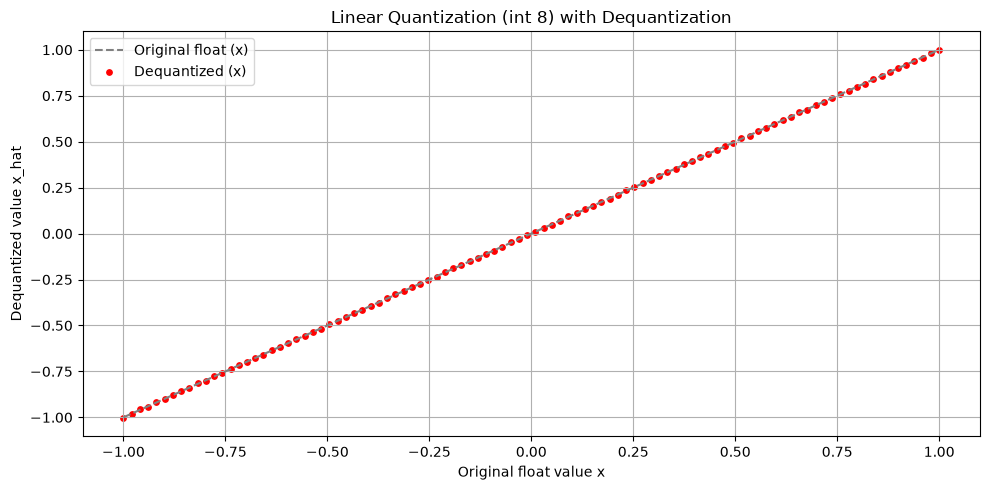

In [8]:
# Plot original vs. dequantize 

plt.figure(figsize=(10, 5))
plt.plot(x,x,label='Original float (x)', linestyle= '--', color='gray')
plt.scatter(x,x_hat, label='Dequantized (x)', color='red', s= 15)
plt.title('Linear Quantization (int 8) with Dequantization')
plt.xlabel('Original float value x')
plt.ylabel('Dequantized value x_hat')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### NF4 - Normal float Quantization

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# you can also use bits and byte library to get better values for NF4 quantization

# step 1: Define 16 NF4 representative float values 
# These are example NF4 values (manually chosen to mimic a Gaussian distribution)
# In practice, libraries like bitsandbytes  use optimized values 

nf4_values = np.array([
    -1.0, -0.75, -0.5, -0.35, -0.2, -0.1, -0.05, -0.01, 
    0.01, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0
])

# step 2: Simulate original float values
x= np.linspace(-1.0, 1.0, 100)  # 1000 float values between -1 and 1
x[:10]  # Display the first 10 simulated float values

array([-1.        , -0.97979798, -0.95959596, -0.93939394, -0.91919192,
       -0.8989899 , -0.87878788, -0.85858586, -0.83838384, -0.81818182])

In [6]:
# step 3: Quantize x by mapping to the nearest NF4 representative value

def quantize_to_nf4(x_vals, nf4_lut):
    indices = np.argmin(np.abs(x_vals[:,None] - nf4_lut[None,:]), axis=1)
    return nf4_lut[indices]

# Quantize the simulated float values
x_nf4 =  quantize_to_nf4(x, nf4_values)
x_nf4[:10]  # Display the first 10 quantized values

array([-1.  , -1.  , -1.  , -1.  , -1.  , -1.  , -1.  , -0.75, -0.75,
       -0.75])

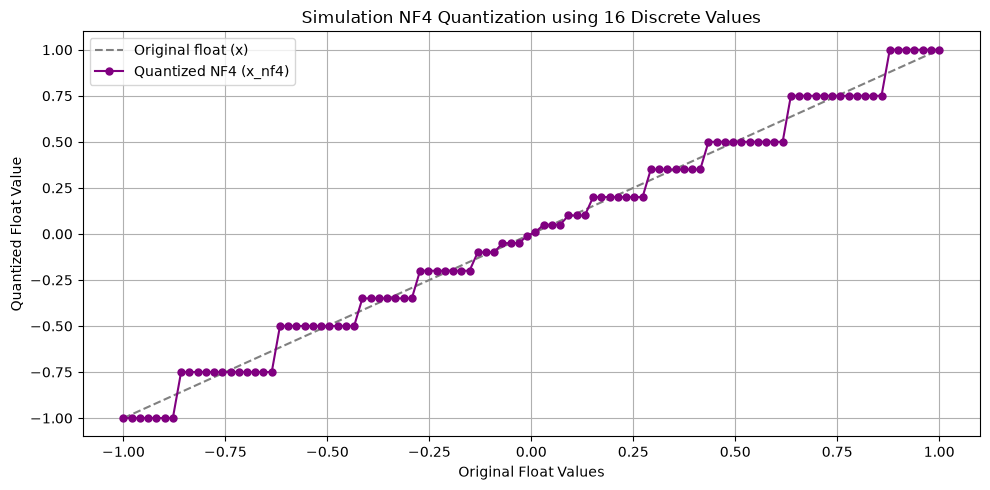

In [7]:
# step 4: Visualize the original and quantized values(NF4)
plt.figure(figsize=(10, 5))
plt.plot(x,x, label='Original float (x)', linestyle='--', color='gray')
plt.plot(x,x_nf4, label='Quantized NF4 (x_nf4)', linestyle='-', color='purple', marker='o', markersize=5)
plt.xlabel('Original Float Values')
plt.ylabel('Quantized Float Value')
plt.title('Simulation NF4 Quantization using 16 Discrete Values')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()